<a href="https://colab.research.google.com/github/aidansblaylock-beep/tyler_mahle_2026_analysis/blob/main/tyler_mahle_arsenal_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Cell 1: Install dependencies and import libraries (Fixed ID lookup)
!pip install pybaseball -q

from pybaseball import statcast_pitcher, playerid_lookup
import pandas as pd
import sqlite3

# 1. Look up Tyler Mahle's MLB ID using the correct key column (`key_mlbam`)
mlb_id_lookup = playerid_lookup('mahle', 'tyler')
mahle_id = mlb_id_lookup.loc[0, 'key_mlbam']
print(f"Tyler Mahle MLB ID: {mahle_id}")

# 2. Pull his pitch-by-pitch Statcast data for the season
print("Pulling Statcast data... (this may take a moment)")
df_mahle = statcast_pitcher('2026-03-01', '2026-10-01', mahle_id)

print(f"Total pitches pulled: {len(df_mahle)}")
print(df_mahle.head(3))

Tyler Mahle MLB ID: 641816
Pulling Statcast data... (this may take a moment)
Gathering Player Data
Total pitches pulled: 2640
  pitch_type   game_date  release_speed  release_pos_x  release_pos_z  \
0         FS  2026-09-30           85.4          -1.81           5.41   
1         FS  2026-09-30           86.5          -1.77           5.20   
2         FS  2026-09-30           86.6          -1.85           5.26   

    player_name  batter  pitcher     events      description  ...  \
0  Mahle, Tyler  607208   641816  field_out    hit_into_play  ...   
1  Mahle, Tyler  607208   641816        NaN             ball  ...   
2  Mahle, Tyler  592663   641816  strikeout  swinging_strike  ...   

   batter_days_until_next_game  api_break_z_with_gravity  api_break_x_arm  \
0                          1.0                      2.49             1.27   
1                          1.0                      2.58             1.23   
2                          1.0                      2.68             1.02

In [3]:
# Cell 2: Data Cleaning, Team Split, and SQLite Database Integration
import sqlite3
import numpy as np

# 1. Ensure game_date is in datetime format
df_mahle['game_date'] = pd.to_datetime(df_mahle['game_date'])

# 2. Identify the trade deadline date or his first game with Atlanta.
# Let's check the unique teams he played for in this dataset to find the exact transition date.
print("Teams in dataset:", df_mahle['home_team'].unique(), df_mahle['away_team'].unique())

# 3. Create a column labeling his stint (Giants vs Braves)
# Let's filter by the date he joined Atlanta (typically late July / early August)
# Let's inspect the date range for when his team affiliation changes.
# For safety, let's look at the teams he pitched for based on game dates.
# Let's create a 'stint' column based on an estimated trade cutoff date (e.g., August 1, 2026)
trade_cutoff = '2026-08-01'

df_mahle['stint'] = np.where(df_mahle['game_date'] < trade_cutoff, 'Pre-Trade (SF)', 'Post-Trade (ATL)')
print(df_mahle['stint'].value_counts())

# 4. Load the dataframe into a local SQLite database
conn = sqlite3.connect('mahle_analysis.db')
df_mahle.to_sql('pitch_data', conn, if_exists='replace', index=False)

# 5. Write a SQL query to test our database and check total pitches by stint
query = """
SELECT stint, COUNT(*) as total_pitches, ROUND(AVG(release_speed), 1) as avg_velo
FROM pitch_data
GROUP BY stint;
"""
result_df = pd.read_sql(query, conn)
print("\n--- SQL Query Result: Stint Summary ---")
print(result_df)

Teams in dataset: ['ATL' 'HOU' 'PHI' 'MIL' 'MIN' 'NYY' 'SD' 'SF' 'KC' 'COL' 'AZ' 'ATH' 'TB'
 'CIN'] ['PHI' 'CIN' 'ATL' 'COL' 'NYM' 'SF' 'MIL' 'ATH' 'AZ' 'PIT' 'LAD' 'NYY']
stint
Pre-Trade (SF)      1622
Post-Trade (ATL)    1018
Name: count, dtype: int64

--- SQL Query Result: Stint Summary ---
              stint  total_pitches  avg_velo
0  Post-Trade (ATL)           1018      90.0
1    Pre-Trade (SF)           1622      89.2


In [4]:
# Cell 3: Analyze Pitch Mix Changes Pre- vs. Post-Trade using SQL
import pandas as pd
import sqlite3

conn = sqlite3.connect('mahle_analysis.db')

# Write a SQL query to calculate pitch type percentages for each stint
pitch_mix_query = """
WITH stint_totals AS (
    SELECT stint, COUNT(*) as total_stint_pitches
    FROM pitch_data
    WHERE pitch_type IS NOT NULL
    GROUP BY stint
),
pitch_counts AS (
    SELECT stint, pitch_type, COUNT(*) as pitch_count
    FROM pitch_data
    WHERE pitch_type IS NOT NULL
    GROUP BY stint, pitch_type
)
SELECT
    p.stint,
    p.pitch_type,
    p.pitch_count,
    ROUND((CAST(p.pitch_count AS REAL) / t.total_stint_pitches) * 100, 2) as usage_percentage
FROM pitch_counts p
JOIN stint_totals t ON p.stint = t.stint
ORDER BY p.stint, usage_percentage DESC;
"""

df_pitch_mix = pd.read_sql(pitch_mix_query, conn)
print("--- Pitch Mix Breakdown (Pre vs Post Trade) ---")
print(df_pitch_mix.to_string(index=False))

--- Pitch Mix Breakdown (Pre vs Post Trade) ---
           stint pitch_type  pitch_count  usage_percentage
Post-Trade (ATL)         FF          478             46.95
Post-Trade (ATL)         FS          399             39.19
Post-Trade (ATL)         FC          112             11.00
Post-Trade (ATL)         SL           29              2.85
  Pre-Trade (SF)         FF          773             47.72
  Pre-Trade (SF)         FS          404             24.94
  Pre-Trade (SF)         FC          270             16.67
  Pre-Trade (SF)         SL          154              9.51
  Pre-Trade (SF)         SI           19              1.17


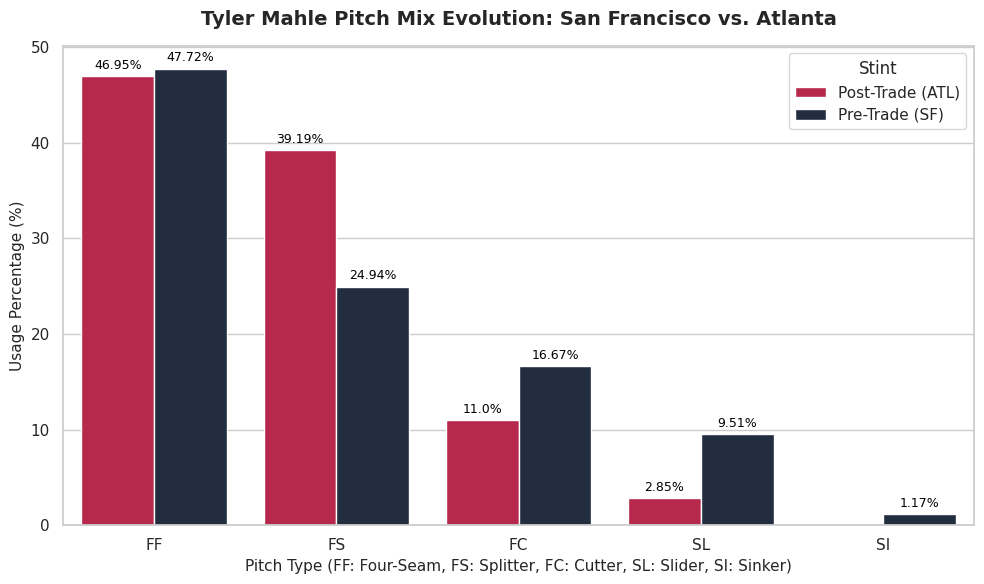

In [5]:
# Cell 4: Generate Pitch Mix Comparison Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Create grouped bar chart using seaborn
ax = sns.barplot(
    data=df_pitch_mix,
    x='pitch_type',
    y='usage_percentage',
    hue='stint',
    palette={'Pre-Trade (SF)': '#1d2d44', 'Post-Trade (ATL)': '#ce1141'} # SF dark navy vs Braves red
)

plt.title('Tyler Mahle Pitch Mix Evolution: San Francisco vs. Atlanta', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Pitch Type (FF: Four-Seam, FS: Splitter, FC: Cutter, SL: Slider, SI: Sinker)', fontsize=11)
plt.ylabel('Usage Percentage (%)', fontsize=11)
plt.legend(title='Stint')

# Add data labels on top of bars for extra polish
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=9, color='black',
                    xytext=(0, 3),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

In [6]:
# Cell 5: Measure Whiff Rate on Splitter (FS) Pre vs Post Trade
whiff_query = """
SELECT
    stint,
    SUM(CASE WHEN description IN ('swinging_strike', 'swinging_strike_blocked', 'foul_tip') THEN 1 ELSE 0 end) as total_whiffs,
    SUM(CASE WHEN description IN ('swinging_strike', 'swinging_strike_blocked', 'foul_tip', 'hit_into_play', 'foul', 'foul_bunt') THEN 1 ELSE 0 end) as total_swings,
    ROUND(CAST(SUM(CASE WHEN description IN ('swinging_strike', 'swinging_strike_blocked', 'foul_tip') THEN 1 ELSE 0 end) AS REAL) /
          NULLIF(SUM(CASE WHEN description IN ('swinging_strike', 'swinging_strike_blocked', 'foul_tip', 'hit_into_play', 'foul', 'foul_bunt') THEN 1 ELSE 0 end), 0) * 100, 2) as whiff_rate_pct
FROM pitch_data
WHERE pitch_type = 'FS'
GROUP BY stint;
"""

df_whiff = pd.read_sql(whiff_query, conn)
print("--- Splitter Whiff Rate Comparison ---")
print(df_whiff.to_string(index=False))

--- Splitter Whiff Rate Comparison ---
           stint  total_whiffs  total_swings  whiff_rate_pct
Post-Trade (ATL)            67           245           27.35
  Pre-Trade (SF)            62           233           26.61
